## Dependencias

In [1]:
import joblib
import shap
import pandas as pd 
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from sklearn.ensemble import RandomForestClassifier
from xgboost import plot_importance

## Carga de conjuntos de datos utilizados para entrenar los modelos.

In [2]:
X_train_final = pd.read_excel(r"C:\Users\Morena\TP2\data\processed\X_train_final.xlsx", index_col = 0)
y_train = pd.read_excel(r"C:\Users\Morena\TP2\data\processed\y_train.xlsx", index_col = 0)
X_test_final = pd.read_excel(r"C:\Users\Morena\TP2\data\processed\X_test_final.xlsx", index_col = 0)
y_test = pd.read_excel(r"C:\Users\Morena\TP2\data\processed\y_test.xlsx", index_col = 0)

## Analisis de datos en base a los modelos entrenados

### Importancia relativa de atributos

#### Random Forest

In [3]:
clf_rf = joblib.load(r"C:\Users\Morena\TP2\objects\models\modelo_random_forest.pkl")

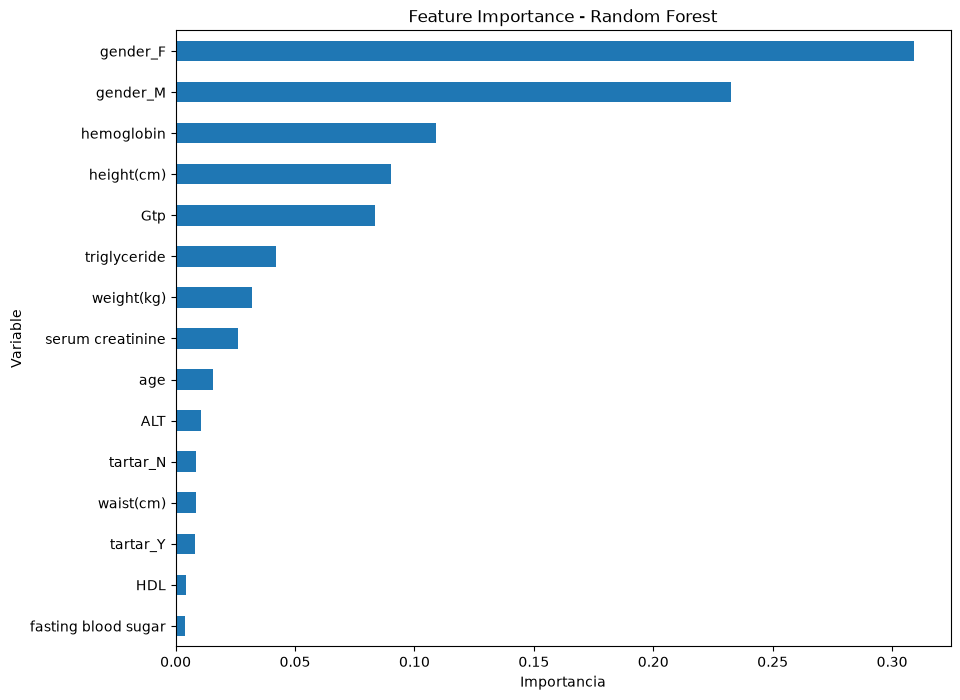

In [4]:
plt.figure(figsize=(10,8))
importances = pd.Series(clf_rf.feature_importances_, index = X_train_final.columns).sort_values(ascending=False)
importances.head(15).plot(kind = "barh")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.title("Feature Importance - Random Forest")
plt.gca().invert_yaxis()
plt.show()

#### XGBoost

In [5]:
clf_xgb = joblib.load(r"C:\Users\Morena\TP2\objects\models\modelo_XGBoost.pkl")

<Figure size 1000x800 with 0 Axes>

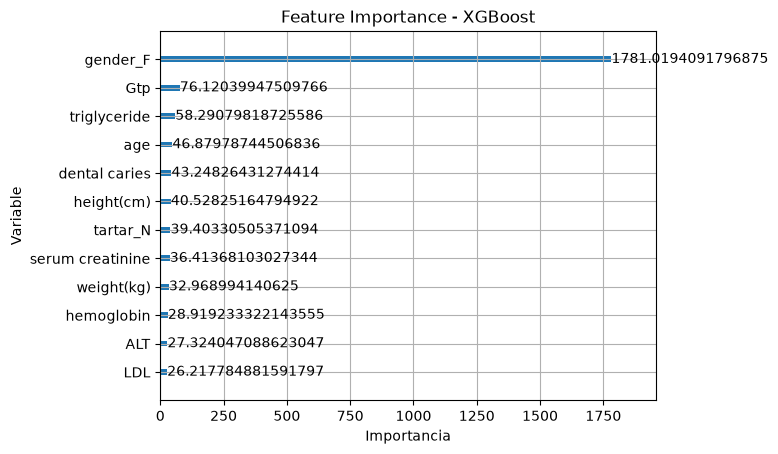

In [6]:
plt.figure(figsize=(10,8))
plot_importance(clf_xgb, max_num_features=12, importance_type="gain")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.title("Feature Importance - XGBoost")
plt.show()

<Figure size 1000x800 with 0 Axes>

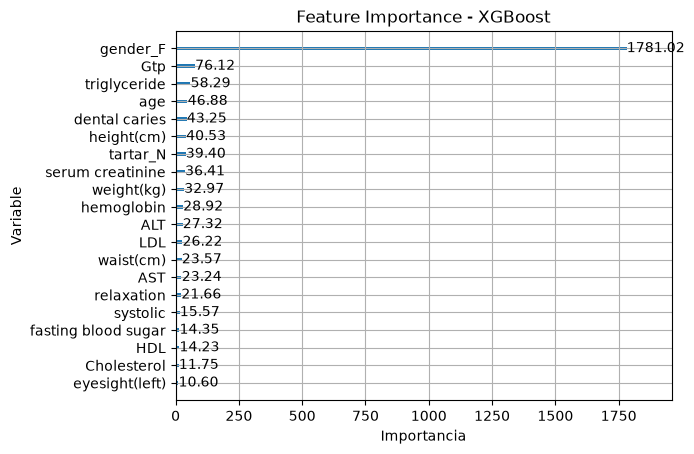

In [7]:
# lo grafico de otra forma para redondear los decimales

plt.figure(figsize=(10,8))
ax = plot_importance(clf_xgb, max_num_features=20, importance_type="gain")

# Iterando sobre los textos de las barras y los redondeamos
for text in ax.texts:
    val = float(text.get_text())
    text.set_text(f"{val:.2f}")  # Limito a 2 decimales
    
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.title("Feature Importance - XGBoost")
plt.show()

In [8]:
# se observa que para el modelo XGBoost, el sexo femenino es la variable mas importante para predecir si una persona será
# fumadora, siguiendo la enzima hepática Gtp y luego los triglicéridos.

### Shap Values

#### Random Forest

In [9]:
# creo un objeto para el modelo RF

explainer_rf = shap.TreeExplainer(clf_rf)

In [10]:
# calculo los shap_values para el conjunto de datos de entrenamiento

shap_values_rf = explainer_rf.shap_values(X_train_final)

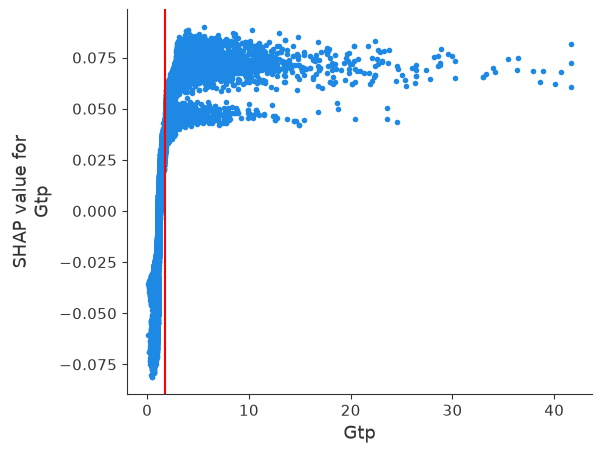

In [11]:
# genero el gráfico de dependencia de la variable Gtp
# le dibujo una linea vertical en el valor Gtp=1.71 , que es el que observé en el EDA como valor significativo.

shap.dependence_plot("Gtp", shap_values_rf[:,:,1], X_train_final, show=False, interaction_index=None)
plt.axvline(1.71, color="red")
plt.show()

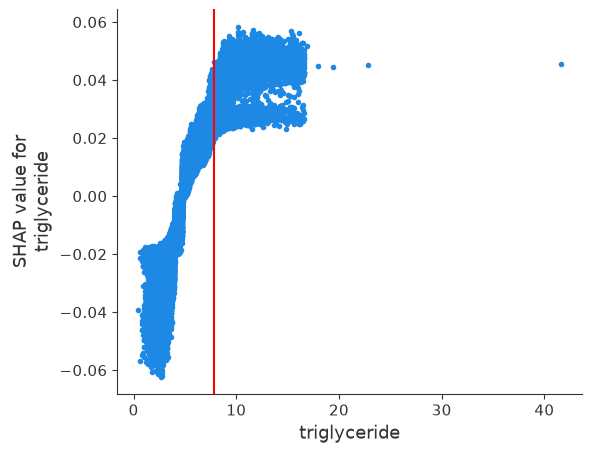

In [12]:
# genero el gráfico de dependencia de la variable triglyceride
# le dibujo una linea vertical en el valor 7.8 , que es el que observé en el EDA como valor significativo.

shap.dependence_plot("triglyceride", shap_values_rf[:,:,1], X_train_final, show=False, interaction_index=None)
plt.axvline(7.8, color="red")
plt.show()

#### XGBoost

In [13]:
# creo un objeto para el modelo XGB

explainer_xgb = shap.TreeExplainer(clf_xgb)

In [14]:
# calculo los shap_values para el conjunto de datos de entrenamiento

shap_values_xgb = explainer_xgb.shap_values(X_train_final)

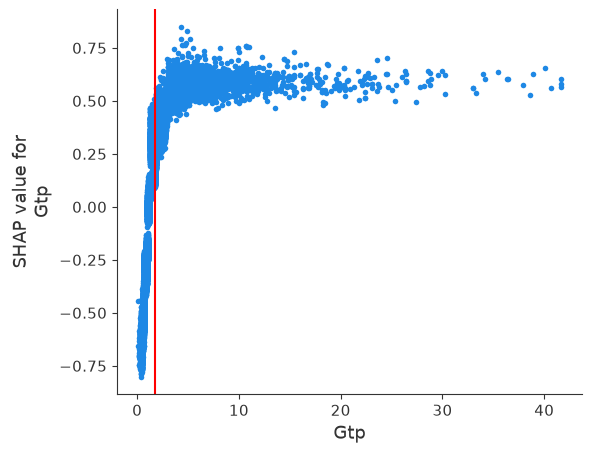

In [15]:
# genero el grafico de dependencia de la variable Gtp
# le dibujo una linea vertical en el valor Gtp=1.71 , que es el que observé en el EDA como valor significativo.

shap.dependence_plot("Gtp", shap_values_xgb, X_train_final, show=False, interaction_index=None)
plt.axvline(1.71, color="red")
plt.show()

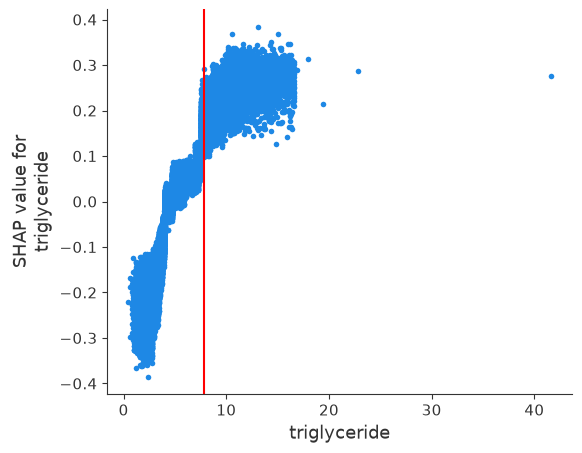

In [16]:
# genero el grafico de dependencia de la variable triglicéridos
# le dibujo una linea vertical en el valor 7.8 , que es el que observé como valor significativo en el EDA.

shap.dependence_plot("triglyceride", shap_values_xgb, X_train_final, show=False, interaction_index=None)
plt.axvline(7.8, color="red")
plt.show()

## Validación de datos

### Arbol de decisión (Train = 73.22% - Test = 72.79%)

In [17]:
# Si bien durante el entrenamiento del modelo Arbol de Decisión, en el reporte de clasificación obtuve un Accuracy de 0,73 en ambos
# conjuntos de datos (train y test), realizo la verificación de aciertos sobre ambos conjuntos de datos, 
# comparando lo predicho por el modelo, y los datos reales de los conjuntos.

In [18]:
# realizo una copia de los conjuntos "y_train" e "y_test" en "y_train_dtc" e "y_test_dtc" respectivamente

In [19]:
y_train_dtc = y_train.copy()

In [20]:
y_test_dtc = y_test.copy()

In [21]:
# Cargo el modelo generado con el método Arbol de decisión

clf_dtc = joblib.load(r"C:\Users\Morena\TP2\objects\models\modelo_arbol_decision.pkl")

In [22]:
# genero las predicciones

In [23]:
%%time
train_pred_dtc = clf_dtc.predict(X_train_final)
test_pred_dtc = clf_dtc.predict(X_test_final)

CPU times: total: 46.9 ms
Wall time: 47.5 ms


In [24]:
train_pred_dtc

array([1, 0, 0, ..., 1, 0, 1], shape=(35000,))

In [25]:
y_train_dtc , y_test_dtc

(       smoking
 8319         1
 7833         0
 27390        0
 44413        1
 24218        0
 ...        ...
 48892        0
 25727        0
 18911        0
 25680        0
 43737        1
 
 [35000 rows x 1 columns],
        smoking
 28092        1
 46589        0
 130          1
 33481        0
 34477        0
 ...        ...
 27265        0
 47956        1
 22181        1
 27516        1
 9154         0
 
 [15000 rows x 1 columns])

In [71]:
# a los conjunto de datos originales, les agrego la columna "smoking_prediction" con los valores predichos por el modelo:

In [27]:
y_train_dtc["smoking_prediction"] = train_pred_dtc

In [28]:
y_test_dtc["smoking_prediction"] = test_pred_dtc

In [29]:
# verifico las estructuras

In [30]:
y_train_dtc , y_test_dtc

(       smoking  smoking_prediction
 8319         1                   1
 7833         0                   0
 27390        0                   0
 44413        1                   1
 24218        0                   0
 ...        ...                 ...
 48892        0                   0
 25727        0                   0
 18911        0                   1
 25680        0                   0
 43737        1                   1
 
 [35000 rows x 2 columns],
        smoking  smoking_prediction
 28092        1                   1
 46589        0                   1
 130          1                   0
 33481        0                   0
 34477        0                   0
 ...        ...                 ...
 27265        0                   0
 47956        1                   1
 22181        1                   1
 27516        1                   1
 9154         0                   0
 
 [15000 rows x 2 columns])

In [31]:
# y realizo la comparación entre las columnas "smoking" y "smoking_prediction" en ambos conjuntos:

In [32]:
comparacion_train_dtc = y_train_dtc["smoking"].eq(y_train_dtc["smoking_prediction"])

In [33]:
comparacion_test_dtc = y_test_dtc["smoking"].eq(y_test_dtc["smoking_prediction"])

In [34]:
print(comparacion_train_dtc.value_counts())

True     25627
False     9373
Name: count, dtype: int64


In [35]:
print(comparacion_test_dtc.value_counts())

True     10918
False     4082
Name: count, dtype: int64


In [72]:
# visualizo los porcentajes de coincidencias, en ambos conjuntos.

In [37]:
print(f"\nPorcentaje de coincidencia en Train: {comparacion_train_dtc.mean()*100:.2f}%")


Porcentaje de coincidencia en Train: 73.22%


In [38]:
print(f"\nPorcentaje de coincidencia en Test: {comparacion_test_dtc.mean()*100:.2f}%")


Porcentaje de coincidencia en Test: 72.79%


### Random Forest (Train = 75.85% - Test = 74.74%)

In [73]:
# Si bien durante el entrenamiento del modelo Random Forest, en el reporte de clasificación obtuve un Accuracy de 0,76 en en el conjunto  
# de entrenamiento y de 0,75 en el conjunto de test, realizo la verificación de aciertos sobre ambos conjuntos.

In [40]:
# realizo una copia de los conjuntos "y_train" e "y_test"

In [41]:
y_train_rf = y_train.copy()

In [42]:
y_test_rf = y_test.copy()

In [43]:
# cargo el modelo Random Forest guardado, en el objeto "clf_rf"

In [44]:
clf_rf = joblib.load(r"C:\Users\Morena\TP2\objects\models\modelo_random_forest.pkl")

In [45]:
%%time
train_pred_rf = clf_rf.predict(X_train_final)
test_pred_rf = clf_rf.predict(X_test_final)

CPU times: total: 516 ms
Wall time: 549 ms


In [46]:
y_train_rf , y_test_rf

(       smoking
 8319         1
 7833         0
 27390        0
 44413        1
 24218        0
 ...        ...
 48892        0
 25727        0
 18911        0
 25680        0
 43737        1
 
 [35000 rows x 1 columns],
        smoking
 28092        1
 46589        0
 130          1
 33481        0
 34477        0
 ...        ...
 27265        0
 47956        1
 22181        1
 27516        1
 9154         0
 
 [15000 rows x 1 columns])

In [47]:
y_train_rf["smoking_prediction"] = train_pred_rf

In [48]:
y_test_rf["smoking_prediction"] = test_pred_rf

In [49]:
y_train_rf , y_test_rf

(       smoking  smoking_prediction
 8319         1                   0
 7833         0                   0
 27390        0                   0
 44413        1                   1
 24218        0                   0
 ...        ...                 ...
 48892        0                   0
 25727        0                   0
 18911        0                   0
 25680        0                   0
 43737        1                   1
 
 [35000 rows x 2 columns],
        smoking  smoking_prediction
 28092        1                   1
 46589        0                   1
 130          1                   0
 33481        0                   0
 34477        0                   0
 ...        ...                 ...
 27265        0                   1
 47956        1                   0
 22181        1                   1
 27516        1                   1
 9154         0                   0
 
 [15000 rows x 2 columns])

In [50]:
comparacion_train_rf = y_train_rf["smoking"].eq(y_train_rf["smoking_prediction"])

In [51]:
comparacion_test_rf = y_test_rf["smoking"].eq(y_test_rf["smoking_prediction"])

In [52]:
print(comparacion_train_rf.value_counts())

True     26549
False     8451
Name: count, dtype: int64


In [53]:
print(comparacion_test_rf.value_counts())

True     11211
False     3789
Name: count, dtype: int64


In [54]:
print(f"\nPorcentaje de coincidencia en Train: {comparacion_train_rf.mean()*100:.2f}%")


Porcentaje de coincidencia en Train: 75.85%


In [55]:
print(f"\nPorcentaje de coincidencia en Test: {comparacion_test_rf.mean()*100:.2f}%")


Porcentaje de coincidencia en Test: 74.74%


### XGBoost (Train = 76.57%- Test = 75.85%)

In [56]:
# Si bien durante el entrenamiento del modelo XGBoost, en el reporte de clasificación obtuve un Accuracy de 0,77 en en el conjunto  
# de entrenamiento y de 0,76 en el conjunto de test, realizo la verificación de aciertos sobre ambos conjuntos de datos.

In [57]:
y_train_xgb = y_train.copy()

In [58]:
y_test_xgb = y_test.copy()

In [59]:
clf_xgb = joblib.load(r"C:\Users\Morena\TP2\objects\models\modelo_XGBoost.pkl")

In [60]:
%%time
train_pred_xgb = clf_xgb.predict(X_train_final)
test_pred_xgb = clf_xgb.predict(X_test_final)

CPU times: total: 281 ms
Wall time: 105 ms


In [61]:
y_train_xgb , y_test_xgb

(       smoking
 8319         1
 7833         0
 27390        0
 44413        1
 24218        0
 ...        ...
 48892        0
 25727        0
 18911        0
 25680        0
 43737        1
 
 [35000 rows x 1 columns],
        smoking
 28092        1
 46589        0
 130          1
 33481        0
 34477        0
 ...        ...
 27265        0
 47956        1
 22181        1
 27516        1
 9154         0
 
 [15000 rows x 1 columns])

In [62]:
y_train_xgb["smoking_prediction"] = train_pred_xgb

In [63]:
y_test_xgb["smoking_prediction"] = test_pred_xgb

In [64]:
y_train_xgb , y_test_xgb

(       smoking  smoking_prediction
 8319         1                   1
 7833         0                   0
 27390        0                   0
 44413        1                   1
 24218        0                   0
 ...        ...                 ...
 48892        0                   0
 25727        0                   0
 18911        0                   0
 25680        0                   0
 43737        1                   1
 
 [35000 rows x 2 columns],
        smoking  smoking_prediction
 28092        1                   1
 46589        0                   1
 130          1                   0
 33481        0                   0
 34477        0                   0
 ...        ...                 ...
 27265        0                   0
 47956        1                   0
 22181        1                   1
 27516        1                   0
 9154         0                   0
 
 [15000 rows x 2 columns])

In [65]:
comparacion_train_xgb = y_train_xgb["smoking"].eq(y_train_xgb["smoking_prediction"])

In [66]:
comparacion_test_xgb = y_test_xgb["smoking"].eq(y_test_xgb["smoking_prediction"])

In [67]:
print(comparacion_train_xgb.value_counts())

True     26801
False     8199
Name: count, dtype: int64


In [68]:
print(comparacion_test_xgb.value_counts())

True     11378
False     3622
Name: count, dtype: int64


In [69]:
print(f"\nPorcentaje de coincidencia en Train es: {comparacion_train_xgb.mean()*100:.2f}%")


Porcentaje de coincidencia en Train es: 76.57%


In [70]:
print(f"\nPorcentaje de coincidencia en Test es: {comparacion_test_xgb.mean()*100:.2f}%")


Porcentaje de coincidencia en Test es: 75.85%
